# Importing important libraries 

In [52]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading Our Dataset on which we have to perform task.

In [2]:
df = pd.read_csv("Telco_Customer_Churn_Dataset  (3).csv")

# Making a copy of dataset , such that our original data remains safe

In [3]:
df_new = df.copy()

# Understanding Dataset

3 Dataset shape
4 First 10 rows
5 Data types
6 Missing-value analysis
7 Dataset information
8 Initial observations

In [4]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df_new.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [6]:
df_new.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

TotalCharges represents object datatype , but it holding numeric values and , we will investigate it futher in this project.

In [7]:
df_new.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

No null values were detected using isnull(). However, potential hidden/malformed missing values may still exist and should be investigated during cleaning.

1.The dataset contains 7,043 customer records and 21 attributes.
2.The dataset contains demographic, service, contract, payment, and billing information.
3.Churn represents the customer outcome that will be analyzed throughout the project.
4.No explicit null values were detected using isnull().
5.TotalCharges is stored as an object datatype even though it represents numerical
charge information and therefore requires further investigation.
6.Several categorical variables will require group-wise analysis in later stages.

# Shows how many blank spaces are there in the TotalCharges column 

In [8]:
df_new["TotalCharges"].str.isspace().sum()

np.int64(11)

Fill the empty space with nan


In [9]:
df_new["TotalCharges"] = df_new["TotalCharges"].replace("", np.nan)
df_new["TotalCharges"] = df_new["TotalCharges"].replace(" ", np.nan)

Converting datatype to float

In [10]:
df_new["TotalCharges"] = df_new["TotalCharges"].astype(float)

In [11]:
df_new["TotalCharges"].dtypes

dtype('float64')

In [12]:
df_new["TotalCharges"].isna().sum()

np.int64(11)

TotalCharges: Converted from object to float64. The column contains 11 missing values, which will be handled appropriately before analysis.

# Cheaking Duplicate values 

In [13]:
df_new.duplicated().sum()

np.int64(0)

In [14]:
df_new["customerID"].duplicated().sum()

np.int64(0)

So there is nothing to remove for duplicates.

In [15]:
df_new.columns = df_new.columns.str.lower()

In [16]:
df_new.columns = df_new.columns.str.replace(" ", "_")

In [17]:
df_new.columns

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='object')

Replacing "totalcharges"[NAN] to 0 , because the customer with [NAN] totalcharges , have "tenure" os 0 months , so that make a "totalcharges" = 0

In [18]:
df_new.loc[df_new["totalcharges"].isna(),"totalcharges"] = 0

In [19]:
df_new["totalcharges"].isna().sum()

np.int64(0)

monthly charges being non-zero does not contradict total charges being zero. monthlycharges represents the recurring/service charge, while totalcharges represents the amount accumulated so far.

In [20]:
df_new[df_new["totalcharges"] == 0][["tenure", "monthlycharges", "totalcharges"]]

,tenure,monthlycharges,totalcharges
488,0,52.55,0.0
753,0,20.25,0.0
936,0,80.85,0.0
1082,0,25.75,0.0
1340,0,56.05,0.0
3331,0,19.85,0.0
3826,0,25.35,0.0
4380,0,20.00,0.0
5218,0,19.70,0.0
6670,0,73.35,0.0


In [21]:
df_new.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

Initially, 11 missing values were identified in totalcharges. All 11 corresponded to customers with zero tenure, so they were replaced with 0 based on the logical relationship between tenure and accumulated charges. After treatment, no missing values remained.

# EDA ["Exploratary Data Analysis"]

In [22]:
df_new[["tenure", "monthlycharges","totalcharges"]].describe()

,tenure,monthlycharges,totalcharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


# MEAN

In [23]:
df_new[["tenure", "monthlycharges", "totalcharges"]].mean()

tenure              32.371149
monthlycharges      64.761692
totalcharges      2279.734304
dtype: float64

# Median

In [24]:
df_new[["tenure", "monthlycharges", "totalcharges"]].median()

tenure              29.00
monthlycharges      70.35
totalcharges      1394.55
dtype: float64

# Mode

In [25]:
df_new[["tenure", "monthlycharges", "totalcharges"]].mode()

,tenure,monthlycharges,totalcharges
0,1.0,20.05,0.0
1,NaN,NaN,20.2


# AVERAGE TENURE
Average tenure is about 32 months, while median is 29 months.

That's relatively close, although the mean being higher suggests some customers with longer tenures are pulling the average upward.

# MONTHLY CHARGES
Mean = 64.76
Median = 70.35

Here the mean is lower than the median. That's something worth investigating when we visualize the distribution.

# TOTAL CHARGES
Mean = 2,279.73
Median = 1,394.55

That's a large difference.

This is a signal that totalcharges may have a right-skewed distribution, where some customers have substantially higher accumulated charges.

# Distribution Analysis

How number of customer may vary over a whole tenure period, including the starting, middle and the end of the services?

Text(0, 0.5, 'Number of Customers')

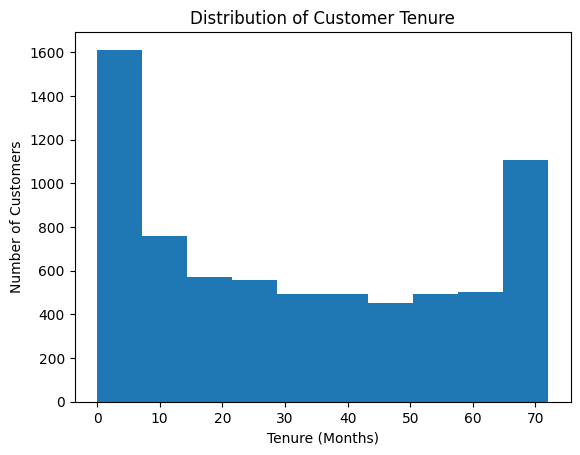

In [26]:
plt.hist(df_new["tenure"])
plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

Customer counts are high at very low tenure levels, decrease through the middle tenure range, and rise again among customers with very high tenure.

How does customer churn vary across different monthly-charge ranges?

Text(0, 0.5, 'Number of customers')

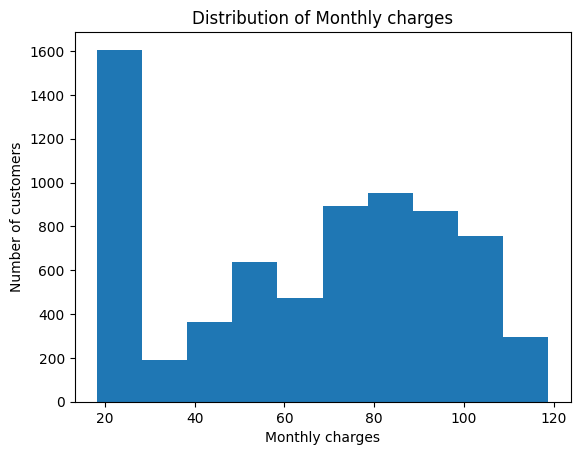

In [27]:
plt.hist(df_new["monthlycharges"])
plt.title("Distribution of Monthly charges")
plt.xlabel("Monthly charges")
plt.ylabel("Number of customers")

Monthly charges show a strong concentration at the lower charge range, followed by another substantial concentration around 70–105. The mean (64.76) is below the median (70.35), indicating a negatively skewed distribution.

How customer churn may vary across different total charges?

Are customers with lower total charges mostly newer customers, and does their churn rate differ from that of longer-tenure customers?

Text(0, 0.5, 'Customers Count')

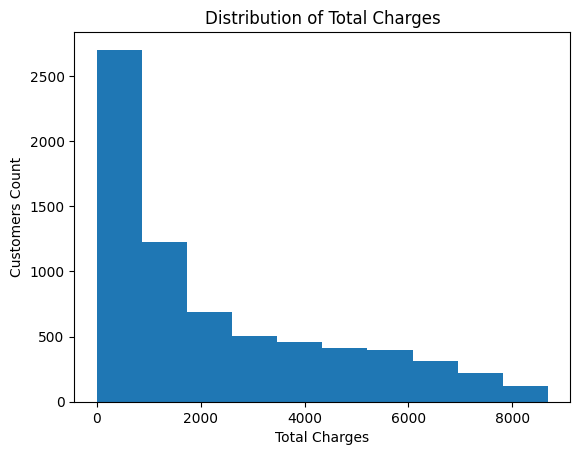

In [28]:
plt.hist(df_new["totalcharges"])
plt.title("Distribution of Total Charges")
plt.xlabel("Total Charges")
plt.ylabel("Customers Count")

The distribution of total charges is strongly right skewed, with a high concentration of customers at lower accumulated charges and there is a fewer customers at higher charges level.

<Axes: >

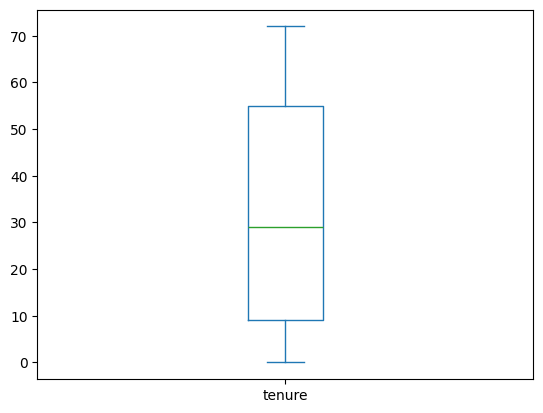

In [29]:
df_new["tenure"].plot.box()

<Axes: >

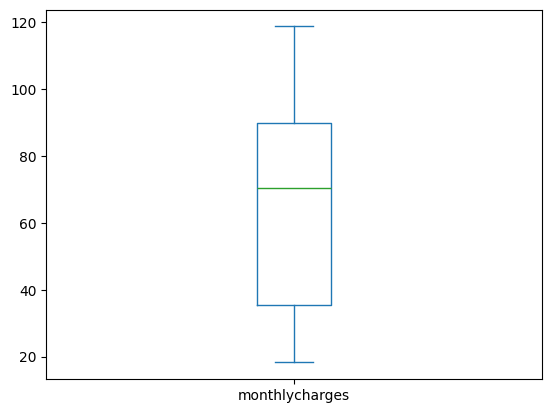

In [30]:
df_new["monthlycharges"].plot.box()

<Axes: >

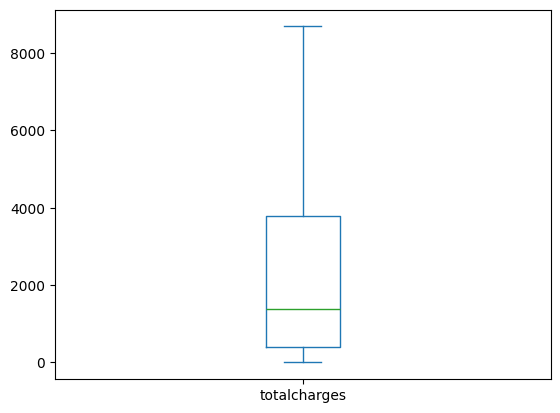

In [31]:
df_new["totalcharges"].plot.box()

# Churn distribution

how many customers churn , how many stayed?
% of churn customers 
churn is an issue?

In [32]:
df_new["churn"].value_counts()

churn
No     5174
Yes    1869
Name: count, dtype: int64

In [33]:
df_new["churn"].value_counts(normalize = True) * 100

churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

Out Of the 7,043 customers, 1,869 (26.54%) churned, while 5,174 (73.46%) remained. Approximately one in four customers in the dataset has churned.

“How much churn is there?” to “Which customer groups have higher churn?”

In [34]:
print(pd.crosstab(df_new["contract"], df_new["churn"]))

churn             No   Yes
contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [35]:
print(pd.crosstab(
    df_new["contract"],
    df_new["churn"],
    normalize="index"
) * 100)

churn                  No        Yes
contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


Month-to-month customers have a much higher churn rate than customers on one-year or two-year contracts.
Churn is strongly associated with contract type in this dataset. The month-to-month group has the highest observed churn rate.
The company should investigate what makes month-to-month customers more likely to leave, such as pricing, service experience, or customer

Find out whether churn rates differ across payment methods.

In [36]:
pd.crosstab(df_new["paymentmethod"], df_new["churn"])

churn,No,Yes
paymentmethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [37]:
print(pd.crosstab(
    df_new["paymentmethod"],
    df_new["churn"],
    normalize="index"
) * 100)

churn                             No        Yes
paymentmethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


Customers using electronic checks have a churn rate of 45.29%, while customers using automatic credit card payments have the lowest churn rate at 15.24%.Electronic check customers are leaving at a substantially higher rate than customers using other payment methods. Their churn rate is almost three times that of automatic credit card customers.The company may be losing a significant number of customers who pay by electronic check.

In [38]:
pd.crosstab(df_new["internetservice"], df_new["churn"])

churn,No,Yes
internetservice,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [39]:
print(pd.crosstab(
    df_new["internetservice"],
    df_new["churn"],
    normalize="index"
) * 100)

churn                   No        Yes
internetservice                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


Customers using Fiber optic internet have the highest churn rate at 41.89%, compared with 18.96% for DSL customers and 7.40% for customers without internet service.Fiber optic customers churn at approximately 2.2 times the rate of DSL customers. This suggests a strong association between fiber optic service and customer churn in this dataset.

In [42]:
pd.crosstab(df_new["onlinesecurity"], df_new["churn"])

churn,No,Yes
onlinesecurity,,
No,2037,1461
No internet service,1413,113
Yes,1724,295


In [43]:
print(pd.crosstab(
    df_new["onlinesecurity"],
    df_new["churn"],
    normalize = "index"
)*100)

churn                       No        Yes
onlinesecurity                           
No                   58.233276  41.766724
No internet service  92.595020   7.404980
Yes                  85.388806  14.611194


Customers without online security have the highest churn rate at 41.77%. Customers with online security have a churn rate of 14.61%.Customers without online security may represent a group worth investigating for retention opportunities

In [ ]:
bins = [-1, 12, 36, float("inf")]
labels = ["0–12 months", "13–36 months", "37+ months"]

df_new["tenure_group"] = pd.cut(
    df_new["tenure"],
    bins=bins,
    labels=labels
)

In [45]:
print(df_new["tenure_group"].value_counts().sort_index())

tenure_group
0–12 months     2186
13–36 months    1856
37+ months      3001
Name: count, dtype: int64


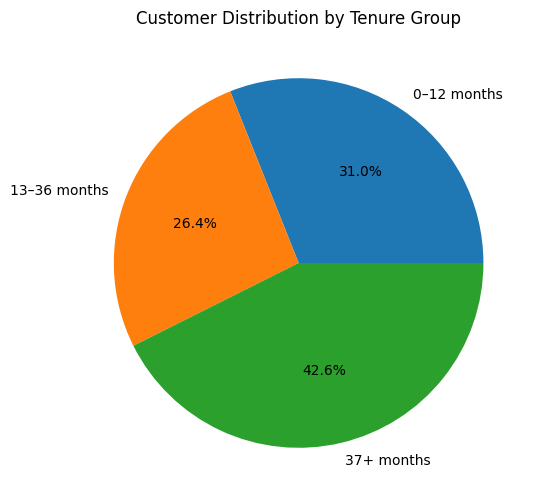

In [61]:
tenure_counts = df_new["tenure_group"].value_counts().sort_index()

plt.figure(figsize=(8, 6))

plt.pie(
    tenure_counts,
    labels=tenure_counts.index,
    autopct="%1.1f%%"
)

plt.title("Customer Distribution by Tenure Group")
plt.show()

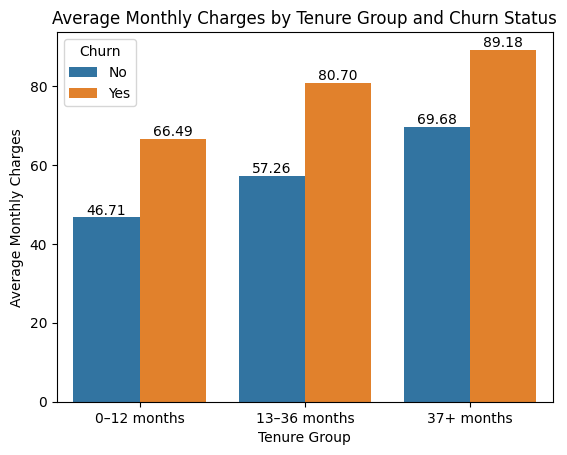

In [64]:
avg_charges = df_new.groupby(
    ["tenure_group", "churn"],
    observed=False
)["monthlycharges"].mean().reset_index()

ax = sns.barplot(
    data=avg_charges,
    x="tenure_group",
    y="monthlycharges",
    hue="churn"
)

ax.bar_label(ax.containers[0], fmt="%.2f")
ax.bar_label(ax.containers[1], fmt="%.2f")

plt.title("Average Monthly Charges by Tenure Group and Churn Status")
plt.xlabel("Tenure Group")
plt.ylabel("Average Monthly Charges")
plt.legend(title="Churn")
plt.show()

Average monthly charges are higher among churned customers than retained customers in all three tenure groups.The largest difference in average monthly charges is in the 13–36 month group, at 23.44. Across all tenure groups, churned customers have higher average monthly charges.

# Advance Analysis

does churn differ between male and female customers?

In [65]:
pd.crosstab(df_new["gender"], df_new["churn"])

churn,No,Yes
gender,,
Female,2549,939
Male,2625,930


In [66]:
pd.crosstab(df_new["gender"],
            df_new["churn"],
            normalize="index") *100 

churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


Female customers have a churn rate of 26.92%, compared with 26.16% for male customers.Gender alone does not appear to be a strong factor for distinguishing customers who churn in this dataset.

In [67]:
pd.crosstab(df_new["seniorcitizen"], df_new["churn"])

churn,No,Yes
seniorcitizen,,
0,4508,1393
1,666,476


In [68]:
pd.crosstab(df_new["seniorcitizen"],
            df_new["churn"],
            normalize="index") *100 

churn,No,Yes
seniorcitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


Non-senior citizens (0): 23.61% churn rate

Senior citizens (1): 41.68% churn rate


Senior citizens have a churn rate approximately 18.08 percentage points higher than non-senior citizens. Their churn rate is about 1.77 times as high.

In [69]:
pd.crosstab(df_new["tenure_group"], df_new["churn"])

churn,No,Yes
tenure_group,,
0–12 months,1149,1037
13–36 months,1382,474
37+ months,2643,358


In [70]:
pd.crosstab(df_new["tenure_group"],
            df_new["churn"],
            normalize="index") *100 

churn,No,Yes
tenure_group,,
0–12 months,52.561757,47.438243
13–36 months,74.461207,25.538793
37+ months,88.070643,11.929357


Customers with 0–12 months of tenure have the highest churn rate (47.44%), while customers with 37+ months have the lowest (11.93%).Churn decreases as tenure increases across these three groups. The early-tenure group has a churn rate nearly 4 times that of the 37+ months group.

average monthly charges by tenure group.

In [72]:
df_new.groupby("tenure_group")["monthlycharges"].mean()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20580\1740250187.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_new.groupby("tenure_group")["monthlycharges"].mean()


tenure_group
0–12 months     56.097781
13–36 months    63.248195
37+ months      72.008730
Name: monthlycharges, dtype: float64

Average monthly charges increase across the tenure groups, from 56.10 for newer customers to 72.01 for long-tenure customers.Long-tenure customers contribute higher average monthly billing in this dataset. However, this comparison alone does not establish whether higher charges lead to greater loyalty.

In [75]:
df_new.groupby("tenure_group")["totalcharges"].mean()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20580\1704564646.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_new.groupby("tenure_group")["totalcharges"].mean()


tenure_group
0–12 months      275.229597
13–36 months    1513.541756
37+ months      4213.723192
Name: totalcharges, dtype: float64

Customers with 37+ months of tenure have much higher cumulative charges than newer customers. This is expected to some extent because longer-tenure customers have had more time to accumulate charges.Consider both customer tenure and monthly charges when evaluating customer value. Avoid assuming that long-tenure customers are necessarily more profitable, because costs and discounts have not been included in this analysis.

# Churn-Rate Summary

In [82]:
churn_rate = df_new["churn"].map(
    {"Yes": 1, "No": 0}).groupby(df_new["tenure_group"]).mean() * 100
churn_rate


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20580\1753235992.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  {"Yes": 1, "No": 0}).groupby(df_new["tenure_group"]).mean() * 100


tenure_group
0–12 months     47.438243
13–36 months    25.538793
37+ months      11.929357
Name: churn, dtype: float64

Text(0, 0.5, 'Churn Rate (%)')

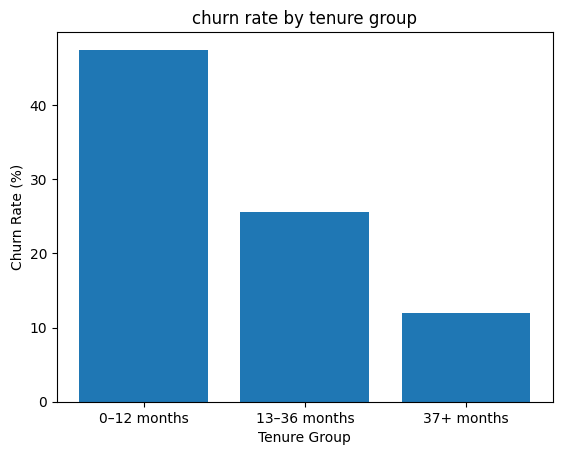

In [84]:
plt.bar(churn_rate.index, churn_rate.values)
plt.title("churn rate by tenure group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")